## Análisis del funnel de conversión

El primer objetivo del análisis es entender cómo avanzan los usuarios a través
de las principales etapas de StyleMatch.

El funnel considerado es:

Visit → Signup → Upload Clothing → Generate Outfit → Save Outfit

Se analizará cuántos usuarios llegan a cada etapa, la tasa de conversión entre
etapas y el porcentaje de abandono, con el objetivo de identificar los
principales puntos de fricción del producto.

In [2]:
import pandas as pd
import numpy as np

In [3]:
users = pd.read_csv("../data/raw/users.csv")
events = pd.read_csv("../data/raw/events.csv")
retention = pd.read_csv("../data/raw/retention.csv")

In [4]:
users["signup_date"] = pd.to_datetime(users["signup_date"])
events["timestamp"] = pd.to_datetime(events["timestamp"])

In [5]:
funnel_order = [
    "visit",
    "signup",
    "upload_clothing",
    "generate_outfit",
    "save_outfit"
]

funnel_counts = (
    events.groupby("event")["user_id"]
    .nunique()
    .reindex(funnel_order)
)

funnel_counts

event
visit              50000
signup             39966
upload_clothing    27988
generate_outfit    21008
save_outfit        12660
Name: user_id, dtype: int64

In [6]:
funnel_analysis = pd.DataFrame({
    "users": funnel_counts
})

funnel_analysis["conversion_rate"] = (
    funnel_analysis["users"]
    / funnel_analysis["users"].shift(1)
    * 100
)

funnel_analysis["dropoff_rate"] = (
    100 - funnel_analysis["conversion_rate"]
)

# La primera etapa es nuestro punto de partida
funnel_analysis.loc["visit", "conversion_rate"] = 100
funnel_analysis.loc["visit", "dropoff_rate"] = 0

funnel_analysis.round(2)

,users,conversion_rate,dropoff_rate
event,,,
visit,50000,100.00,0.00
signup,39966,79.93,20.07
upload_clothing,27988,70.03,29.97
generate_outfit,21008,75.06,24.94
save_outfit,12660,60.26,39.74


### Hallazgo: principal punto de abandono del funnel

El funnel muestra una disminución progresiva de usuarios a medida que avanzan
por las diferentes etapas de StyleMatch.

La mayor tasa de abandono ocurre entre `generate_outfit` y `save_outfit`,
donde aproximadamente el 39,74 % de los usuarios que generan un outfit
no llegan a guardarlo.

También se observa una caída relevante entre `signup` y `upload_clothing`,
con un abandono cercano al 29,97 %.

Estos resultados sugieren que sería importante investigar qué factores pueden
estar dificultando que los usuarios encuentren suficiente valor en los outfits
generados como para decidir guardarlos.

In [7]:
# Unir los eventos con el canal de adquisición de cada usuario
events_with_users = events.merge(
    users[["user_id", "acquisition_channel"]],
    on="user_id",
    how="left"
)

events_with_users.head()

,user_id,event,timestamp,acquisition_channel
0,U00001,visit,2026-04-12 23:03:00,Organic
1,U00002,visit,2026-06-28 23:17:00,Google Ads
2,U00002,signup,2026-06-28 23:21:00,Google Ads
3,U00002,upload_clothing,2026-06-28 23:37:00,Google Ads
4,U00002,generate_outfit,2026-06-28 23:39:00,Google Ads


In [8]:
# Contar usuarios únicos por canal y etapa del funnel
funnel_by_channel = (
    events_with_users
    .groupby(["acquisition_channel", "event"])["user_id"]
    .nunique()
    .unstack()
)

# Ordenar las columnas según el recorrido del funnel
funnel_by_channel = funnel_by_channel[funnel_order]

funnel_by_channel

event,visit,signup,upload_clothing,generate_outfit,save_outfit
acquisition_channel,,,,,
Google Ads,9918,7865,5454,4122,2506
Instagram,12336,9935,7067,5289,3204
Organic,10112,8021,5608,4212,2522
Referral,5082,4071,2851,2107,1222
TikTok,12552,10074,7008,5278,3206


In [9]:
# Calcular conversión desde la visita inicial hasta cada etapa
conversion_by_channel = (
    funnel_by_channel
    .div(funnel_by_channel["visit"], axis=0)
    .mul(100)
    .round(2)
)

conversion_by_channel

event,visit,signup,upload_clothing,generate_outfit,save_outfit
acquisition_channel,,,,,
Google Ads,100.0,79.30,54.99,41.56,25.27
Instagram,100.0,80.54,57.29,42.87,25.97
Organic,100.0,79.32,55.46,41.65,24.94
Referral,100.0,80.11,56.10,41.46,24.05
TikTok,100.0,80.26,55.83,42.05,25.54


### Hallazgo: conversión por canal de adquisición

La conversión acumulada desde la visita inicial hasta el guardado de un outfit
es similar entre los diferentes canales de adquisición.

La conversión final se encuentra aproximadamente entre el 24 % y el 26 % en
todos los canales. Instagram presenta una conversión del 25,97 %, mientras que
Referral registra un 24,05 %.

Las diferencias observadas son pequeñas, por lo que el canal de adquisición no
parece ser un factor determinante para explicar el abandono del funnel dentro
de los datos analizados.

Esto sugiere que el principal punto de abandono identificado anteriormente
podría estar relacionado con otros factores del producto o con características
de los usuarios.

In [10]:
# Unir los eventos con las características de cada usuario
events_with_users = events.merge(
    users[["user_id", "acquisition_channel", "country"]],
    on="user_id",
    how="left"
)

events_with_users.head()

,user_id,event,timestamp,acquisition_channel,country
0,U00001,visit,2026-04-12 23:03:00,Organic,Colombia
1,U00002,visit,2026-06-28 23:17:00,Google Ads,Colombia
2,U00002,signup,2026-06-28 23:21:00,Google Ads,Colombia
3,U00002,upload_clothing,2026-06-28 23:37:00,Google Ads,Colombia
4,U00002,generate_outfit,2026-06-28 23:39:00,Google Ads,Colombia


In [11]:
# Contar usuarios únicos por país y etapa del funnel
funnel_by_country = (
    events_with_users
    .groupby(["country", "event"])["user_id"]
    .nunique()
    .unstack()
)

# Ordenar las columnas según el recorrido del funnel
funnel_by_country = funnel_by_country[funnel_order]

funnel_by_country

event,visit,signup,upload_clothing,generate_outfit,save_outfit
country,,,,,
Argentina,7473,5947,4154,3104,1896
Chile,7684,6209,4345,3304,2035
Colombia,19914,15889,11150,8342,4959
Mexico,10028,7980,5601,4201,2511
Peru,4901,3941,2738,2057,1259


In [12]:
# Calcular conversión desde la visita inicial hasta cada etapa
conversion_by_country = (
    funnel_by_country
    .div(funnel_by_country["visit"], axis=0)
    .mul(100)
    .round(2)
)

conversion_by_country

event,visit,signup,upload_clothing,generate_outfit,save_outfit
country,,,,,
Argentina,100.0,79.58,55.59,41.54,25.37
Chile,100.0,80.80,56.55,43.00,26.48
Colombia,100.0,79.79,55.99,41.89,24.90
Mexico,100.0,79.58,55.85,41.89,25.04
Peru,100.0,80.41,55.87,41.97,25.69


### Interpretación de la conversión por país

Las tasas de conversión presentan un comportamiento similar entre los diferentes países analizados.

La conversión desde la visita inicial hasta el guardado del outfit se encuentra aproximadamente entre el 25% y el 26% en todos los países, sin observarse diferencias significativas.

Chile presenta la mayor conversión final con 26.48%, mientras que Colombia presenta la menor con 24.90%. Sin embargo, la diferencia entre ambos países es pequeña.

Esto indica que, dentro de los datos simulados, el país del usuario no parece ser un factor determinante para explicar el abandono observado en el funnel.

In [13]:
# Calcular conversión y abandono entre etapas consecutivas
step_analysis = pd.DataFrame({
    "users": funnel_counts
})

step_analysis["step_conversion"] = (
    step_analysis["users"]
    / step_analysis["users"].shift(1)
    * 100
)

step_analysis["step_dropoff"] = 100 - step_analysis["step_conversion"]

# La primera etapa no tiene una etapa anterior
step_analysis.loc["visit", "step_conversion"] = 100
step_analysis.loc["visit", "step_dropoff"] = 0

step_analysis.round(2)

,users,step_conversion,step_dropoff
event,,,
visit,50000,100.00,0.00
signup,39966,79.93,20.07
upload_clothing,27988,70.03,29.97
generate_outfit,21008,75.06,24.94
save_outfit,12660,60.26,39.74


### Identificación del principal punto de abandono

El análisis entre etapas consecutivas muestra que el mayor abandono del funnel ocurre entre `generate_outfit` y `save_outfit`.

Solo el 60.26% de los usuarios que generan un outfit terminan guardándolo, lo que representa un abandono del 39.74%.

Este comportamiento identifica la etapa final del funnel como el principal punto de fricción del producto. Los usuarios llegan a utilizar la funcionalidad principal de StyleMatch, pero una parte importante no completa la acción de guardar el resultado.

Sin embargo, estos datos permiten identificar dónde ocurre el abandono, pero no explican directamente su causa. Será necesario analizar otras métricas para entender mejor este comportamiento.

In [14]:
# Unir información de retención con los eventos de los usuarios
retention_with_events = retention.merge(
    events[["user_id", "event"]],
    on="user_id",
    how="left"
)

retention_with_events.head(10)

,user_id,day_1,day_7,day_30,event
0,U00002,False,True,False,visit
1,U00002,False,True,False,signup
2,U00002,False,True,False,upload_clothing
3,U00002,False,True,False,generate_outfit
4,U00002,False,True,False,save_outfit
5,U00003,True,False,False,visit
6,U00003,True,False,False,signup
7,U00004,True,False,False,visit
8,U00004,True,False,False,signup
9,U00005,False,False,False,visit


In [15]:
# Asignar un nivel numérico a cada etapa del funnel
stage_map = {
    "visit": 1,
    "signup": 2,
    "upload_clothing": 3,
    "generate_outfit": 4,
    "save_outfit": 5
}

retention_with_events["stage_number"] = (
    retention_with_events["event"].map(stage_map)
)

# Encontrar la etapa máxima alcanzada por cada usuario
max_stage = (
    retention_with_events
    .groupby("user_id")["stage_number"]
    .max()
)

max_stage.value_counts().sort_index()

stage_number
2    11978
3     6980
4     8348
5    12660
Name: count, dtype: int64

In [16]:
# Crear una tabla con una fila por usuario y su etapa máxima alcanzada
user_retention_analysis = retention.merge(
    max_stage.rename("max_stage"),
    on="user_id",
    how="left"
)

# Convertir el número de etapa nuevamente a su nombre
stage_names = {
    2: "signup",
    3: "upload_clothing",
    4: "generate_outfit",
    5: "save_outfit"
}

user_retention_analysis["max_stage_name"] = (
    user_retention_analysis["max_stage"].map(stage_names)
)

user_retention_analysis.head(10)

,user_id,day_1,day_7,day_30,max_stage,max_stage_name
0,U00002,False,True,False,5,save_outfit
1,U00003,True,False,False,2,signup
2,U00004,True,False,False,2,signup
3,U00005,False,False,False,3,upload_clothing
4,U00006,False,False,False,5,save_outfit
5,U00008,True,False,True,4,generate_outfit
6,U00009,False,True,False,2,signup
7,U00010,True,False,False,2,signup
8,U00011,True,False,False,5,save_outfit
9,U00015,True,True,False,4,generate_outfit


In [17]:
# Calcular retención promedio según la etapa máxima alcanzada
retention_by_stage = (
    user_retention_analysis
    .groupby("max_stage_name")[["day_1", "day_7", "day_30"]]
    .mean()
    .mul(100)
    .round(2)
)

# Ordenar las etapas
stage_order = [
    "signup",
    "upload_clothing",
    "generate_outfit",
    "save_outfit"
]

retention_by_stage = retention_by_stage.reindex(stage_order)

retention_by_stage

,day_1,day_7,day_30
max_stage_name,,,
signup,54.88,34.88,19.35
upload_clothing,54.58,35.06,19.86
generate_outfit,55.10,34.34,19.18
save_outfit,54.67,34.64,19.87


### Relación entre avance en el funnel y retención

Las tasas de retención son muy similares independientemente de la etapa máxima alcanzada por los usuarios.

En Day 1, la retención se mantiene aproximadamente entre 54% y 55%; en Day 7, alrededor del 34% al 35%; y en Day 30, cerca del 19% al 20%.

No se observa un incremento consistente de la retención a medida que los usuarios avanzan hacia etapas más profundas del funnel. Por ejemplo, los usuarios que llegan hasta `save_outfit` presentan una retención Day 30 de 19.87%, mientras que quienes solo llegan hasta `signup` presentan 19.35%.

Por lo tanto, dentro de estos datos simulados, avanzar más en el funnel no parece estar fuertemente asociado con una mayor retención.

In [18]:
# Calcular nuevos usuarios registrados por mes
users_by_month = (
    users
    .set_index("signup_date")
    .resample("ME")["user_id"]
    .nunique()
)

users_by_month

signup_date
2026-01-31    8635
2026-02-28    7608
2026-03-31    8675
2026-04-30    8254
2026-05-31    8576
2026-06-30    8252
Freq: ME, Name: user_id, dtype: int64

In [19]:
# Calcular promedio diario de nuevos usuarios por mes
daily_signup_rate = (
    users_by_month
    / users_by_month.index.days_in_month
).round(2)

daily_signup_rate

signup_date
2026-01-31    278.55
2026-02-28    271.71
2026-03-31    279.84
2026-04-30    275.13
2026-05-31    276.65
2026-06-30    275.07
Freq: ME, dtype: float64

### Evolución temporal de la adquisición de usuarios

El número total de registros presenta algunas variaciones entre meses. Sin embargo, estas diferencias están parcialmente relacionadas con la cantidad de días de cada mes.

Al calcular el promedio diario de nuevos usuarios, se observa un comportamiento estable durante todo el período analizado, con valores aproximadamente entre 272 y 280 registros diarios.

Por lo tanto, no se identifica una tendencia clara de crecimiento o disminución en la adquisición de usuarios durante el primer semestre de 2026.

Esto sugiere que StyleMatch mantiene un ritmo de adquisición relativamente constante, aunque tampoco se observa un crecimiento sostenido de nuevos usuarios.

In [20]:
# Contar eventos realizados por mes
events_by_month = (
    events
    .set_index("timestamp")
    .resample("ME")["event"]
    .count()
)

events_by_month

timestamp
2025-12-31      637
2026-01-31    26203
2026-02-28    23153
2026-03-31    26279
2026-04-30    24948
2026-05-31    25833
2026-06-30    24569
Freq: ME, Name: event, dtype: int64

In [21]:
# Revisar los eventos que aparecen en diciembre de 2025
december_events = events[
    events["timestamp"] < "2026-01-01"
]

print("Cantidad:", len(december_events))
print("\nTipos de eventos:")
print(december_events["event"].value_counts())

print("\nRango de fechas:")
print(december_events["timestamp"].min())
print(december_events["timestamp"].max())

Cantidad: 637

Tipos de eventos:
event
visit              263
signup             184
upload_clothing     99
generate_outfit     60
save_outfit         31
Name: count, dtype: int64

Rango de fechas:
2025-12-31 23:01:00
2025-12-31 23:59:00


In [22]:
# Revisar los usuarios con eventos en diciembre
december_user_ids = december_events["user_id"].unique()

december_users = users[
    users["user_id"].isin(december_user_ids)
]

print("Usuarios involucrados:", len(december_users))
print("\nFechas de registro:")
print(december_users["signup_date"].value_counts().sort_index().head(10))

Usuarios involucrados: 263

Fechas de registro:
signup_date
2026-01-01    263
Name: count, dtype: int64


In [23]:
# Filtrar los eventos al período oficial del análisis
events_analysis = events[
    (events["timestamp"] >= "2026-01-01") &
    (events["timestamp"] < "2026-07-01")
].copy()

print("Eventos originales:", len(events))
print("Eventos para análisis:", len(events_analysis))
print("Eventos excluidos:", len(events) - len(events_analysis))

Eventos originales: 151622
Eventos para análisis: 150985
Eventos excluidos: 637


### Ajuste del período temporal

Durante el análisis temporal se identificaron 637 eventos registrados el 31 de diciembre de 2025.

Al investigar estos registros, se encontró que pertenecían a 263 usuarios cuya fecha de registro era el 1 de enero de 2026. Esta anomalía se originó durante la generación de los datos sintéticos, debido a que algunos eventos fueron asignados minutos antes de la fecha de registro y cruzaron al día anterior.

Como el período definido para el análisis corresponde a enero-junio de 2026, estos 637 eventos fueron excluidos del análisis temporal.

Los datos originales se mantienen sin modificaciones en `events`, mientras que `events_analysis` contiene únicamente los eventos correspondientes al período oficial de análisis.

In [24]:
# Recalcular eventos mensuales usando el período limpio
events_by_month = (
    events_analysis
    .set_index("timestamp")
    .resample("ME")["event"]
    .count()
)

events_by_month

timestamp
2026-01-31    26203
2026-02-28    23153
2026-03-31    26279
2026-04-30    24948
2026-05-31    25833
2026-06-30    24569
Freq: ME, Name: event, dtype: int64

In [25]:
# Calcular promedio diario de eventos por mes
daily_events_rate = (
    events_by_month
    / events_by_month.index.days_in_month
).round(2)

daily_events_rate

timestamp
2026-01-31    845.26
2026-02-28    826.89
2026-03-31    847.71
2026-04-30    831.60
2026-05-31    833.32
2026-06-30    818.97
Freq: ME, dtype: float64

In [26]:
# Obtener mes de cada evento
events_analysis["month"] = events_analysis["timestamp"].dt.to_period("M")

# Calcular usuarios activos únicos por mes
active_users_by_month = (
    events_analysis
    .groupby("month")["user_id"]
    .nunique()
)

# Calcular eventos por usuario activo
events_per_active_user = (
    events_by_month.values / active_users_by_month.values
).round(2)

monthly_engagement = pd.DataFrame({
    "active_users": active_users_by_month,
    "events": events_by_month.values,
    "events_per_user": events_per_active_user
})

monthly_engagement

,active_users,events,events_per_user
month,,,
2026-01,8712,26203,3.01
2026-02,7681,23153,3.01
2026-03,8691,26279,3.02
2026-04,8354,24948,2.99
2026-05,8640,25833,2.99
2026-06,8047,24569,3.05


In [27]:
# Contar usuarios únicos por tipo de evento y mes
monthly_event_users = (
    events_analysis
    .groupby(["month", "event"])["user_id"]
    .nunique()
    .unstack(fill_value=0)
)

# Ordenar las etapas
monthly_event_users = monthly_event_users[funnel_order]

monthly_event_users

event,visit,signup,upload_clothing,generate_outfit,save_outfit
month,,,,,
2026-01,8647,6921,4864,3621,2150
2026-02,7613,6087,4280,3228,1945
2026-03,8631,6930,4847,3688,2183
2026-04,8300,6621,4548,3419,2060
2026-05,8575,6796,4745,3542,2175
2026-06,7971,6427,4605,3450,2116


In [28]:
# Calcular conversión mensual desde visit hasta cada etapa
monthly_conversion = (
    monthly_event_users
    .div(monthly_event_users["visit"], axis=0)
    .mul(100)
    .round(2)
)

monthly_conversion

event,visit,signup,upload_clothing,generate_outfit,save_outfit
month,,,,,
2026-01,100.0,80.04,56.25,41.88,24.86
2026-02,100.0,79.96,56.22,42.40,25.55
2026-03,100.0,80.29,56.16,42.73,25.29
2026-04,100.0,79.77,54.80,41.19,24.82
2026-05,100.0,79.25,55.34,41.31,25.36
2026-06,100.0,80.63,57.77,43.28,26.55


### Insight

Las tasas de conversión del funnel se mantienen relativamente estables durante el periodo analizado. La conversión de visita a guardado de outfit se mantiene alrededor del 25%, alcanzando su valor más alto en junio con 26.55%.

Esto sugiere que las variaciones mensuales en actividad están relacionadas principalmente con el volumen de usuarios y no con un deterioro del funnel.

In [29]:
# Calcular conversión entre etapas consecutivas por mes
monthly_step_conversion = monthly_event_users.copy().astype(float)

for i in range(1, len(funnel_order)):
    current_stage = funnel_order[i]
    previous_stage = funnel_order[i - 1]

    monthly_step_conversion[current_stage] = (
        monthly_event_users[current_stage]
        / monthly_event_users[previous_stage]
        * 100
    )

monthly_step_conversion["visit"] = 100

monthly_step_conversion.round(2)

event,visit,signup,upload_clothing,generate_outfit,save_outfit
month,,,,,
2026-01,100,80.04,70.28,74.44,59.38
2026-02,100,79.96,70.31,75.42,60.25
2026-03,100,80.29,69.94,76.09,59.19
2026-04,100,79.77,68.69,75.18,60.25
2026-05,100,79.25,69.82,74.65,61.41
2026-06,100,80.63,71.65,74.92,61.33


### Insight: principal punto de abandono

El mayor abandono del funnel ocurre entre `generate_outfit` y `save_outfit`.

Durante el periodo analizado, aproximadamente entre el 59% y el 61% de los usuarios que generan un outfit terminan guardándolo. Esto representa un abandono cercano al 40%, superior al observado en las demás etapas.

El patrón se mantiene estable durante todos los meses analizados, por lo que esta etapa representa una oportunidad importante de mejora en la experiencia del producto.

In [30]:
# Unir los eventos con el dispositivo de cada usuario
events_with_device = events_analysis.merge(
    users[["user_id", "device"]],
    on="user_id",
    how="left"
)

events_with_device.head()

,user_id,event,timestamp,month,device
0,U00001,visit,2026-04-12 23:03:00,2026-04,Web
1,U00002,visit,2026-06-28 23:17:00,2026-06,Web
2,U00002,signup,2026-06-28 23:21:00,2026-06,Web
3,U00002,upload_clothing,2026-06-28 23:37:00,2026-06,Web
4,U00002,generate_outfit,2026-06-28 23:39:00,2026-06,Web


In [31]:
# Contar usuarios únicos por dispositivo y etapa del funnel
funnel_by_device = (
    events_with_device
    .groupby(["device", "event"])["user_id"]
    .nunique()
    .unstack()
)

# Ordenar las etapas del funnel
funnel_by_device = funnel_by_device[funnel_order]

funnel_by_device

event,visit,signup,upload_clothing,generate_outfit,save_outfit
device,,,,,
Android,27463,21930,15443,11582,6933
Web,7446,5922,4194,3154,1931
iOS,14828,11930,8252,6212,3765


In [32]:
# Calcular conversión desde visita hasta cada etapa por dispositivo
conversion_by_device = (
    funnel_by_device
    .div(funnel_by_device["visit"], axis=0)
    .mul(100)
    .round(2)
)

conversion_by_device

event,visit,signup,upload_clothing,generate_outfit,save_outfit
device,,,,,
Android,100.0,79.85,56.23,42.17,25.24
Web,100.0,79.53,56.33,42.36,25.93
iOS,100.0,80.46,55.65,41.89,25.39


### Insight: comportamiento por dispositivo

Las tasas de conversión son muy similares entre Android, Web e iOS durante todo el recorrido del funnel.

La conversión final desde `visit` hasta `save_outfit` se mantiene alrededor del 25% en los tres dispositivos, con diferencias menores a un punto porcentual.

Esto indica que el tipo de dispositivo no parece ser un factor relevante para explicar el abandono de usuarios dentro del funnel.

In [33]:
# Calcular tasas generales de retención
retention_rates = (
    retention[["day_1", "day_7", "day_30"]]
    .mean()
    .mul(100)
    .round(2)
)

retention_rates

day_1     54.81
day_7     34.72
day_30    19.57
dtype: float64

### Insight: retención general

La retención de usuarios disminuye progresivamente con el tiempo. El 54.81% de los usuarios regresa al día 1, el 34.72% al día 7 y el 19.57% permanece retenido al día 30.

Esto muestra una pérdida importante de usuarios durante las primeras semanas posteriores al registro, por lo que entender qué características o comportamientos están asociados con una mayor retención puede representar una oportunidad de mejora para el producto.

In [35]:
# Obtener la etapa máxima alcanzada por cada usuario
stage_map = {
    "visit": 1,
    "signup": 2,
    "upload_clothing": 3,
    "generate_outfit": 4,
    "save_outfit": 5
}

user_max_stage = events.copy()

user_max_stage["stage_number"] = user_max_stage["event"].map(stage_map)

user_max_stage = (
    user_max_stage
    .groupby("user_id")["stage_number"]
    .max()
    .reset_index(name="max_stage")
)

# Convertir número de etapa a nombre
stage_name_map = {v: k for k, v in stage_map.items()}

user_max_stage["max_stage_name"] = (
    user_max_stage["max_stage"].map(stage_name_map)
)

# Unir con retención
retention_with_stage = retention.merge(
    user_max_stage,
    on="user_id",
    how="left"
)

retention_with_stage.head(10)

,user_id,day_1,day_7,day_30,max_stage,max_stage_name
0,U00002,False,True,False,5,save_outfit
1,U00003,True,False,False,2,signup
2,U00004,True,False,False,2,signup
3,U00005,False,False,False,3,upload_clothing
4,U00006,False,False,False,5,save_outfit
5,U00008,True,False,True,4,generate_outfit
6,U00009,False,True,False,2,signup
7,U00010,True,False,False,2,signup
8,U00011,True,False,False,5,save_outfit
9,U00015,True,True,False,4,generate_outfit


In [36]:
# Calcular retención según la etapa máxima alcanzada
retention_by_stage = (
    retention_with_stage
    .groupby("max_stage_name")[["day_1", "day_7", "day_30"]]
    .mean()
    .mul(100)
    .round(2)
)

stage_order = [
    "signup",
    "upload_clothing",
    "generate_outfit",
    "save_outfit"
]

retention_by_stage = retention_by_stage.reindex(stage_order)

retention_by_stage

,day_1,day_7,day_30
max_stage_name,,,
signup,54.88,34.88,19.35
upload_clothing,54.58,35.06,19.86
generate_outfit,55.10,34.34,19.18
save_outfit,54.67,34.64,19.87


### Insight: relación entre funnel y retención

Las tasas de retención son muy similares entre los usuarios que alcanzaron diferentes etapas del funnel.

En Day 30, la retención se mantiene alrededor del 19%–20% independientemente de si el usuario llegó únicamente al registro, subió prendas, generó un outfit o llegó a guardarlo.

Por lo tanto, en estos datos no se observa una relación clara entre avanzar más en el funnel y una mayor retención. Esto sugiere que la retención podría estar relacionada con otros factores que todavía deben ser investigados.

In [37]:
# Unir retención con el canal de adquisición
retention_with_channel = retention.merge(
    users[["user_id", "acquisition_channel"]],
    on="user_id",
    how="left"
)

retention_with_channel.head()

,user_id,day_1,day_7,day_30,acquisition_channel
0,U00002,False,True,False,Google Ads
1,U00003,True,False,False,Google Ads
2,U00004,True,False,False,Instagram
3,U00005,False,False,False,Organic
4,U00006,False,False,False,TikTok


In [38]:
# Calcular retención por canal de adquisición
retention_by_channel = (
    retention_with_channel
    .groupby("acquisition_channel")[["day_1", "day_7", "day_30"]]
    .mean()
    .mul(100)
    .round(2)
)

retention_by_channel

,day_1,day_7,day_30
acquisition_channel,,,
Google Ads,54.85,33.06,19.21
Instagram,54.68,35.27,19.42
Organic,55.07,34.98,19.11
Referral,54.80,36.16,19.16
TikTok,54.70,34.69,20.53


### Insight: retención por canal de adquisición

Las tasas de retención son similares entre los diferentes canales de adquisición.

En Day 30, la retención se mantiene aproximadamente entre el 19% y el 21% para todos los canales. TikTok presenta el valor más alto con 20.53%, aunque la diferencia frente a los demás canales es pequeña.

Por lo tanto, no se observa una relación clara entre el canal de adquisición y la retención de los usuarios en los datos analizados.

In [39]:
# Unir retención con el país de cada usuario
retention_with_country = retention.merge(
    users[["user_id", "country"]],
    on="user_id",
    how="left"
)

# Calcular retención por país
retention_by_country = (
    retention_with_country
    .groupby("country")[["day_1", "day_7", "day_30"]]
    .mean()
    .mul(100)
    .round(2)
)

retention_by_country

,day_1,day_7,day_30
country,,,
Argentina,55.02,33.88,19.79
Chile,53.60,34.77,19.33
Colombia,54.98,35.24,19.97
Mexico,55.24,34.65,19.22
Peru,54.83,33.95,18.70


### Insight: retención por país

Las tasas de retención son similares entre los países analizados.

En Day 30, la retención se encuentra aproximadamente entre el 19% y el 20% en todos los países. Colombia presenta el valor más alto con 19.97% y Perú el más bajo con 18.70%, aunque la diferencia es pequeña.

Por lo tanto, no se observa una relación clara entre el país del usuario y su retención.

In [40]:
# Unir retención con el dispositivo de cada usuario
retention_with_device = retention.merge(
    users[["user_id", "device"]],
    on="user_id",
    how="left"
)

# Calcular retención por dispositivo
retention_by_device = (
    retention_with_device
    .groupby("device")[["day_1", "day_7", "day_30"]]
    .mean()
    .mul(100)
    .round(2)
)

retention_by_device

,day_1,day_7,day_30
device,,,
Android,54.77,34.56,19.74
Web,54.95,34.65,19.24
iOS,54.79,35.05,19.41


### Insight: retención por dispositivo

Las tasas de retención son prácticamente iguales entre los diferentes dispositivos.

En Day 30, Android presenta una retención de 19.74%, iOS de 19.41% y Web de 19.24%. Las diferencias son menores a un punto porcentual.

Por lo tanto, no se observa una relación clara entre el dispositivo utilizado y la retención de los usuarios.

## Visualización de resultados

A continuación se presentan visualmente los principales hallazgos obtenidos durante el análisis de producto de StyleMatch.

In [41]:
import matplotlib.pyplot as plt

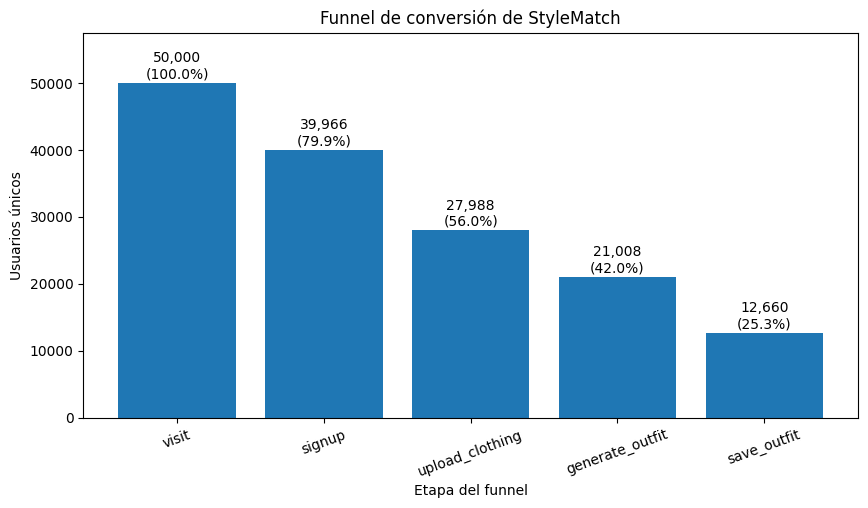

In [43]:
# Visualizar el funnel principal del producto

plt.figure(figsize=(10, 5))

bars = plt.bar(
    funnel_counts.index,
    funnel_counts.values
)

plt.title("Funnel de conversión de StyleMatch")
plt.xlabel("Etapa del funnel")
plt.ylabel("Usuarios únicos")
plt.xticks(rotation=20)

# Mostrar usuarios y conversión total sobre cada barra
initial_users = funnel_counts.iloc[0]

for bar, value in zip(bars, funnel_counts.values):
    conversion = value / initial_users * 100

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 700,
        f"{value:,}\n({conversion:.1f}%)",
        ha="center"
    )

plt.ylim(0, funnel_counts.max() * 1.15)

plt.show()

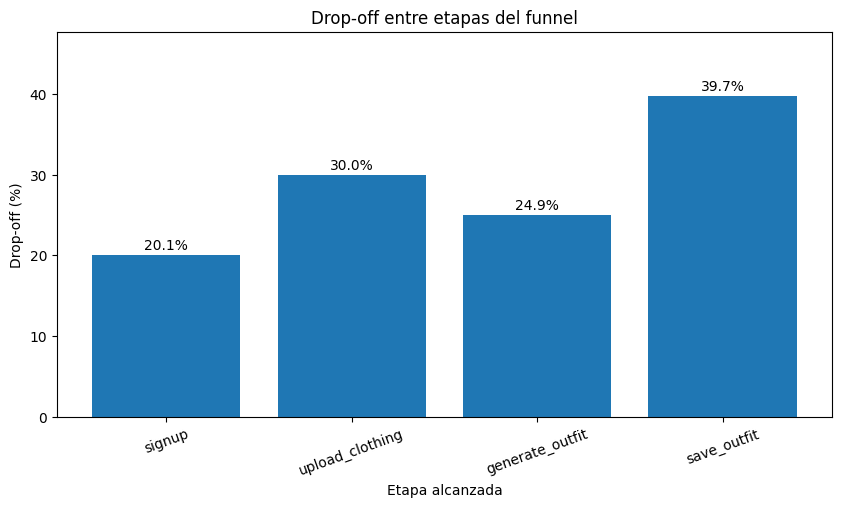

In [44]:
# Excluir visit porque no tiene una etapa anterior
dropoff_plot = step_analysis.drop(index="visit")

plt.figure(figsize=(10, 5))

bars = plt.bar(
    dropoff_plot.index,
    dropoff_plot["step_dropoff"]
)

plt.title("Drop-off entre etapas del funnel")
plt.xlabel("Etapa alcanzada")
plt.ylabel("Drop-off (%)")
plt.xticks(rotation=20)

# Mostrar porcentaje encima de cada barra
for bar, value in zip(bars, dropoff_plot["step_dropoff"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.7,
        f"{value:.1f}%",
        ha="center"
    )

plt.ylim(0, dropoff_plot["step_dropoff"].max() * 1.2)

plt.show()

### Insight: abandono entre etapas del funnel

El mayor punto de abandono del funnel ocurre entre `generate_outfit` y `save_outfit`, donde aproximadamente el 39.7% de los usuarios no continúa a la siguiente etapa.

El segundo mayor abandono ocurre antes de `upload_clothing`, con aproximadamente un 30%.

Estos resultados sugieren que la etapa de guardado del outfit representa la principal oportunidad de investigación y mejora dentro del funnel.

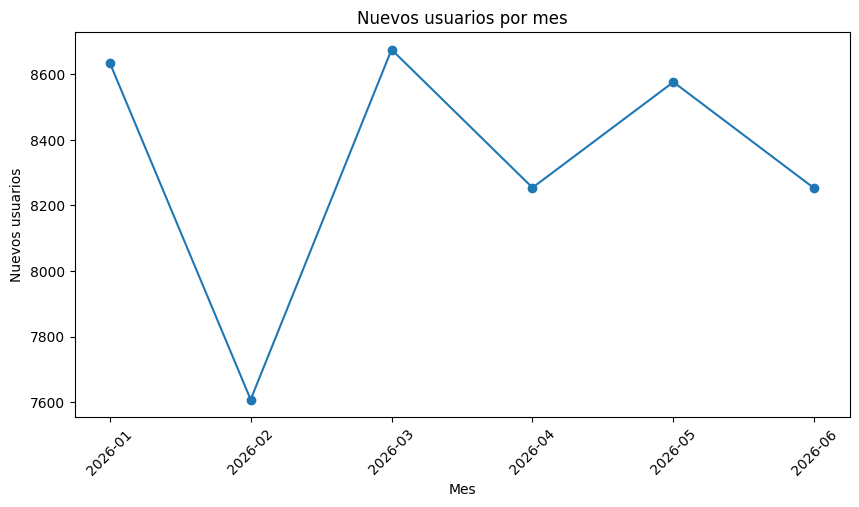

In [47]:
# Visualizar nuevos usuarios por mes

plt.figure(figsize=(10, 5))

months = users_by_month.index.strftime("%Y-%m")

plt.plot(
    months,
    users_by_month.values,
    marker="o"
)

plt.title("Nuevos usuarios por mes")
plt.xlabel("Mes")
plt.ylabel("Nuevos usuarios")

plt.xticks(rotation=45)

plt.show()

### Insight: evolución de nuevos usuarios

El volumen de nuevos usuarios se mantiene relativamente estable durante el periodo analizado, aunque presenta algunas variaciones mensuales.

Febrero registra el menor número de nuevos usuarios, con 7,608, seguido de una recuperación en marzo hasta 8,675 usuarios.

A partir de marzo, el volumen se mantiene alrededor de los 8,000–8,600 nuevos usuarios mensuales, sin observarse una tendencia sostenida de crecimiento o disminución.

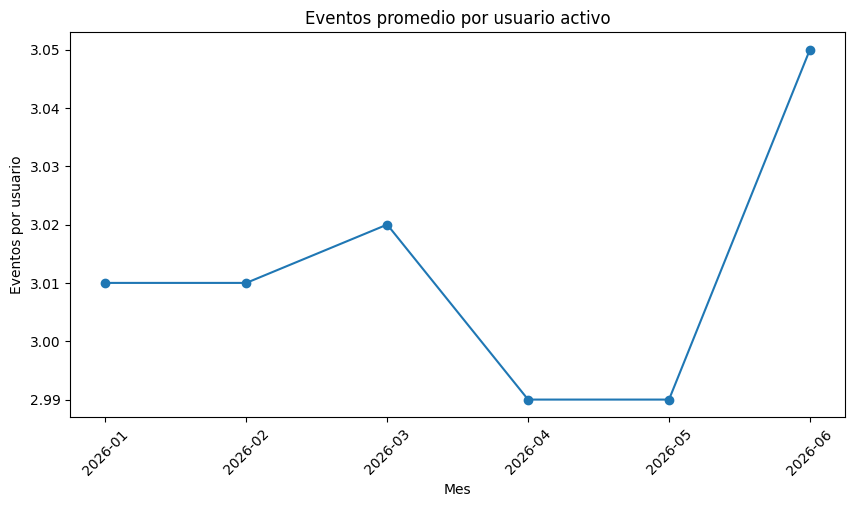

In [49]:
# Visualizar engagement mensual

plt.figure(figsize=(10, 5))

months = monthly_engagement.index.astype(str)

plt.plot(
    months,
    monthly_engagement["events_per_user"],
    marker="o"
)

plt.title("Eventos promedio por usuario activo")
plt.xlabel("Mes")
plt.ylabel("Eventos por usuario")

plt.xticks(rotation=45)

plt.show()

### Insight: engagement mensual

El nivel de engagement de los usuarios se mantiene prácticamente estable durante todo el periodo analizado.

Los usuarios activos realizan aproximadamente 3 eventos por mes en promedio, con valores entre 2.99 y 3.05 eventos por usuario.

Aunque junio presenta el valor más alto, la diferencia respecto a los demás meses es pequeña. Por lo tanto, no se observa una tendencia clara de aumento o disminución en la intensidad de uso del producto.

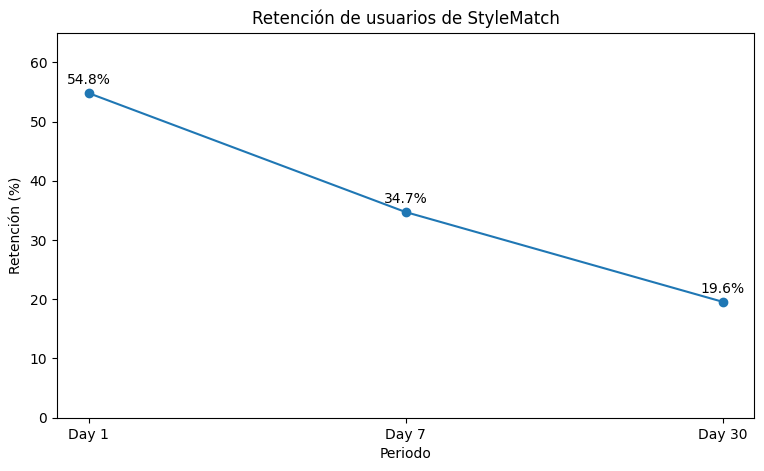

In [50]:
# Visualizar la evolución de la retención

retention_rates = (
    retention[["day_1", "day_7", "day_30"]]
    .mean()
    .mul(100)
)

labels = ["Day 1", "Day 7", "Day 30"]

plt.figure(figsize=(9, 5))

plt.plot(
    labels,
    retention_rates.values,
    marker="o"
)

# Mostrar porcentaje en cada punto
for label, value in zip(labels, retention_rates.values):
    plt.text(
        label,
        value + 1.5,
        f"{value:.1f}%",
        ha="center"
    )

plt.title("Retención de usuarios de StyleMatch")
plt.xlabel("Periodo")
plt.ylabel("Retención (%)")

plt.ylim(0, 65)

plt.show()

### Insight: retención de usuarios

La retención disminuye progresivamente a medida que pasa el tiempo desde el registro.

El 54.8% de los usuarios regresa en Day 1, el 34.7% permanece activo en Day 7 y aproximadamente el 19.6% continúa regresando en Day 30.

Esto muestra que la mayor parte de los usuarios no mantiene su actividad a largo plazo, por lo que la retención representa una oportunidad importante de investigación para StyleMatch.

## Conclusiones y recomendaciones de producto

El análisis de StyleMatch muestra un comportamiento relativamente estable durante el periodo estudiado. El volumen de nuevos usuarios, el engagement y las tasas de conversión no presentan tendencias fuertes de crecimiento o deterioro.

### Principales hallazgos

1. **La conversión total del funnel es del 25.3%.**  
   De 50,000 usuarios que visitan StyleMatch, 12,660 llegan a guardar un outfit.

2. **El mayor abandono ocurre antes de guardar el outfit.**  
   Entre `generate_outfit` y `save_outfit` se pierde aproximadamente el 39.7% de los usuarios, siendo el mayor drop-off del funnel.

3. **La adquisición de usuarios se mantiene relativamente estable.**  
   No se observa una tendencia sostenida de crecimiento o disminución entre enero y junio.

4. **El engagement permanece estable.**  
   Los usuarios activos realizan aproximadamente 3 eventos por mes durante todo el periodo analizado.

5. **La retención disminuye considerablemente con el tiempo.**  
   La retención pasa de 54.8% en Day 1 a 34.7% en Day 7 y 19.6% en Day 30.

6. **Los segmentos analizados presentan comportamientos similares.**  
   País, dispositivo, canal de adquisición y etapa máxima alcanzada no muestran diferencias suficientemente grandes como para explicar por sí solos la retención observada.

### Recomendaciones

- Investigar la experiencia entre `generate_outfit` y `save_outfit` para entender por qué una proporción importante de usuarios genera un outfit pero no lo guarda.
- Analizar qué comportamientos tempranos están relacionados con una mayor retención, especialmente durante los primeros 7 días.
- Realizar experimentos de producto orientados a facilitar o incentivar el guardado de outfits.
- Incorporar métricas de funnel, engagement y retención en un dashboard para monitorear continuamente la salud del producto.

Los resultados permiten identificar oportunidades de investigación y experimentación, pero no permiten determinar por sí solos las causas del abandono o de la pérdida de retención.

## Exportación de datos procesados

Los principales resultados del análisis se exportan como datasets procesados para facilitar su consumo posterior en herramientas de visualización y dashboards.

Los datos originales permanecen sin modificaciones en `data/raw`, mientras que los resultados derivados del análisis se almacenan en `data/processed`.

In [51]:
# Preparar dataset procesado del funnel

funnel_processed = step_analysis.reset_index()

funnel_processed

,event,users,step_conversion,step_dropoff
0,visit,50000,100.000000,0.000000
1,signup,39966,79.932000,20.068000
2,upload_clothing,27988,70.029525,29.970475
3,generate_outfit,21008,75.060740,24.939260
4,save_outfit,12660,60.262757,39.737243


In [52]:
# Redondear porcentajes
funnel_processed["step_conversion"] = funnel_processed["step_conversion"].round(2)
funnel_processed["step_dropoff"] = funnel_processed["step_dropoff"].round(2)

# Exportar
funnel_processed.to_csv(
    "../data/processed/funnel.csv",
    index=False
)

print("funnel.csv guardado correctamente.")

funnel.csv guardado correctamente.


In [53]:
# Preparar resumen general de retención
retention_summary = (
    retention[["day_1", "day_7", "day_30"]]
    .mean()
    .mul(100)
    .round(2)
    .reset_index()
)

retention_summary.columns = ["period", "retention_rate"]

retention_summary

,period,retention_rate
0,day_1,54.81
1,day_7,34.72
2,day_30,19.57


In [54]:
# Exportar resumen de retención

retention_summary.to_csv(
    "../data/processed/retention_summary.csv",
    index=False
)

print("retention_summary.csv guardado correctamente.")

retention_summary.csv guardado correctamente.


In [55]:
# Preparar métricas mensuales para el dashboard

monthly_metrics = monthly_engagement.copy()

# Agregar nuevos usuarios del mes
monthly_metrics["new_users"] = users_by_month.values

# Reordenar columnas
monthly_metrics = monthly_metrics[
    ["new_users", "active_users", "events", "events_per_user"]
]

# Convertir el índice en una columna
monthly_metrics = monthly_metrics.reset_index()

monthly_metrics

,month,new_users,active_users,events,events_per_user
0,2026-01,8635,8712,26203,3.01
1,2026-02,7608,7681,23153,3.01
2,2026-03,8675,8691,26279,3.02
3,2026-04,8254,8354,24948,2.99
4,2026-05,8576,8640,25833,2.99
5,2026-06,8252,8047,24569,3.05


In [56]:
# Exportar métricas mensuales

monthly_metrics.to_csv(
    "../data/processed/monthly_metrics.csv",
    index=False
)

print("monthly_metrics.csv guardado correctamente.")

monthly_metrics.csv guardado correctamente.


### Datos procesados para segmentación

Se preparan los resultados de conversión por canal de adquisición, país y dispositivo para permitir análisis comparativos posteriores en el dashboard.


In [57]:
# Preparar conversión por canal de adquisición

channel_processed = (
    conversion_by_channel
    .reset_index()
    .round(2)
)

channel_processed

event,acquisition_channel,visit,signup,upload_clothing,generate_outfit,save_outfit
0,Google Ads,100.0,79.30,54.99,41.56,25.27
1,Instagram,100.0,80.54,57.29,42.87,25.97
2,Organic,100.0,79.32,55.46,41.65,24.94
3,Referral,100.0,80.11,56.10,41.46,24.05
4,TikTok,100.0,80.26,55.83,42.05,25.54


In [58]:
# Preparar conversión por país

country_processed = (
    conversion_by_country
    .reset_index()
    .round(2)
)

country_processed

event,country,visit,signup,upload_clothing,generate_outfit,save_outfit
0,Argentina,100.0,79.58,55.59,41.54,25.37
1,Chile,100.0,80.80,56.55,43.00,26.48
2,Colombia,100.0,79.79,55.99,41.89,24.90
3,Mexico,100.0,79.58,55.85,41.89,25.04
4,Peru,100.0,80.41,55.87,41.97,25.69


In [59]:
# Preparar conversión por dispositivo

device_processed = (
    conversion_by_device
    .reset_index()
    .round(2)
)

device_processed

event,device,visit,signup,upload_clothing,generate_outfit,save_outfit
0,Android,100.0,79.85,56.23,42.17,25.24
1,Web,100.0,79.53,56.33,42.36,25.93
2,iOS,100.0,80.46,55.65,41.89,25.39


In [60]:
# Exportar datasets de segmentación

channel_processed.to_csv(
    "../data/processed/conversion_by_channel.csv",
    index=False
)

country_processed.to_csv(
    "../data/processed/conversion_by_country.csv",
    index=False
)

device_processed.to_csv(
    "../data/processed/conversion_by_device.csv",
    index=False
)

print("Datasets de segmentación guardados correctamente.")

Datasets de segmentación guardados correctamente.


## Cierre del análisis

El análisis permitió evaluar el comportamiento de StyleMatch desde cuatro perspectivas principales: adquisición, conversión, engagement y retención.

Los resultados muestran un producto con métricas relativamente estables durante el periodo analizado. Sin embargo, se identifican dos áreas relevantes para continuar investigando: la pérdida de usuarios entre la generación y el guardado de outfits, y la disminución progresiva de la retención hasta Day 30.

Como resultado del análisis se generaron datasets procesados con las principales métricas de producto, preparados para su posterior visualización y monitoreo mediante un dashboard.